## Earlier Monte Carlo working notebook

This file is an earlier pass. The specification discussed in the report (90-day lookback, 10,000 draws, 99% VaR, 2.4% violation rate) is `monte carlo model for VAR_N50 - F.ipynb` in this same folder. The cell below only resolves `data/Nifty50_data.xlsx` so the notebook is not tied to `E:/MSDSM/Sem-4/FCP/MTC`.


In [1]:
# Shared dataset locator.
# The workbook and the two-year CSV live in the project data/ folder.
# Running this notebook from a method folder (Historical, GARCH, ...) or from
# the project root both resolve. Machine-specific paths from the original
# Colab / local drives are no longer required.
from pathlib import Path

def find_nifty_file(filename="Nifty50_data.xlsx"):
    """Return the first existing copy of a file under data/ or the working directory."""
    here = Path.cwd().resolve()
    candidates = [
        here / "data" / filename,
        here.parent / "data" / filename,
        here / filename,
    ]
    for path in candidates:
        if path.exists():
            return str(path.resolve())
    raise FileNotFoundError(
        f"Could not find {filename}. Open the notebook from the project folder "
        "or from its method folder so that data/ is visible."
    )

NIFTY_PATH = find_nifty_file("Nifty50_data.xlsx")
print("Using dataset:", NIFTY_PATH)


E:\MSDSM\Sem-4\FCP\MTC


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns

In [3]:
ticker = 'NVDA'
start_date = '2022-01-01'
end_date = '2023-12-31'
nvidia_data = yf.download(ticker, start=start_date, end=end_date, progress=False)


In [4]:
nvidia_data.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,NVDA,NVDA,NVDA,NVDA,NVDA,NVDA
Date,,,,,,
2022-01-03 00:00:00+00:00,30.070990,30.121000,30.711000,29.785000,29.815001,391547000
2022-01-04 00:00:00+00:00,29.241369,29.290001,30.468000,28.349001,30.277000,527154000
2022-01-05 00:00:00+00:00,27.558165,27.604000,29.416000,27.533001,28.948999,498064000
2022-01-06 00:00:00+00:00,28.131212,28.177999,28.438000,27.065001,27.639999,454186000
2022-01-07 00:00:00+00:00,27.201763,27.247000,28.422001,27.056999,28.141001,409939000


In [7]:
# Parameters
S0 = nvidia_data['Close'].iloc[0] # Initial stock price
T = 1/12    
r = 0.05 
sigma = 0.13
K = 100  
N = 500  
M = 10000 

dt = T / N
t = np.linspace(0, T, N)

# Monte Carlo simulation of GBM paths
np.random.seed(42) 
dW = np.random.normal(0, np.sqrt(dt), (M, N)) 
S = np.zeros((M, N))
S[:, 0] = S0 

# Simulate stock prices
for i in range(1, N):
    S[:, i] = S[:, i-1] * np.exp((r - 0.5 * sigma**2) * dt + sigma * dW[:, i-1])



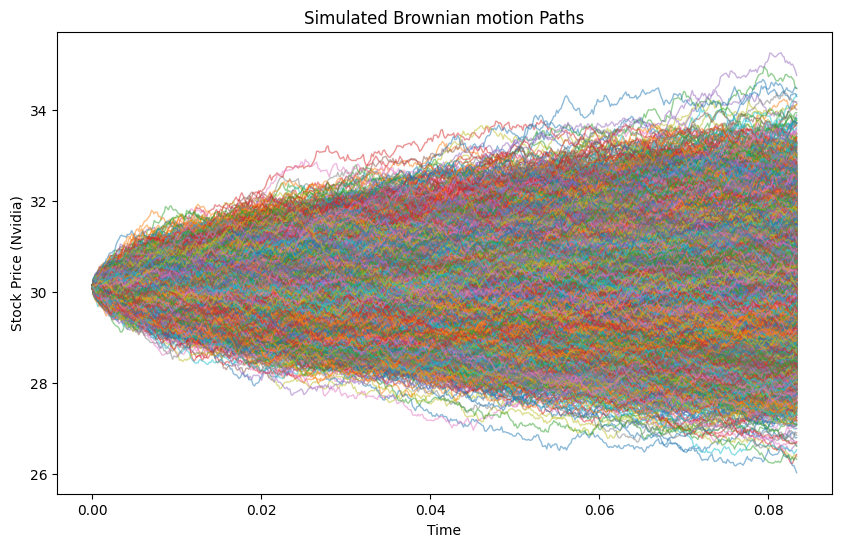

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(t, S.T, lw=1, alpha=0.5)
plt.title("Simulated Brownian motion Paths")
plt.xlabel("Time")
plt.ylabel("Stock Price (Nvidia)")
plt.show()

In [11]:
ST = S[:, -1] 